# Stage 01 – Cora: data and node classification task

**Goal.** Get to know the Cora citation graph and define the node classification task that the graph convolutional network (GCN) of the next stages will solve: what is classified, which features are available and how the papers are linked.

This notebook studies the **raw** data: no feature preprocessing, no model and no training. It does not compare models and contains no classification results.

## 1. Setup

In Google Colab, the next cell installs PyTorch Geometric 2.8.1; the other libraries (PyTorch, NumPy, SciPy, Matplotlib, NetworkX) are preinstalled in the runtime. In a local project environment nothing is installed. The library versions used in the run are listed at the end of the notebook.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install torch_geometric==2.8.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 903.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 8.0 MB/s eta 0:00:00


In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import torch
from torch_geometric.datasets import Planetoid

## 2. Loading Cora

Cora is loaded with the standard **public** Planetoid split. On the first run, the raw files are downloaded from the public Planetoid repository into `data/Planetoid`, relative to the working directory.

In [3]:
dataset = Planetoid(root="data/Planetoid", name="Cora", split="public")
data = dataset[0]
print(data)

Processing...


Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])


Done!


## 3. The graph

- A **node** is a scientific paper about machine learning. A **node index** (0 to 2707) is only the position of the paper in this dataset; Planetoid does not store the original paper IDs.
- An **edge** is a citation link between two papers. The original data record which paper cites which, but in the representation used here the links are **undirected**: the direction of the citation is not preserved.
- `edge_index` stores edges as columns `(source, target)`. An undirected edge between papers `u` and `v` is stored **twice**, as `(u, v)` and `(v, u)`. Therefore the number of undirected edges is half the number of `edge_index` entries, provided that every entry has its reverse and there are no self-loops or duplicate entries.

The cell below checks these properties (and that every index refers to an existing node) before counting the edges.

In [4]:
num_nodes = data.num_nodes
edge_index = data.edge_index
num_entries = edge_index.size(1)

assert edge_index.shape[0] == 2, "edge_index must have shape [2, E]."
assert edge_index.min() >= 0 and edge_index.max() < num_nodes, "Edge indices must refer to existing nodes."

pairs = set(map(tuple, edge_index.t().tolist()))
assert len(pairs) == num_entries, "edge_index must not contain duplicate entries."
assert all(u != v for u, v in pairs), "The raw graph must not contain self-loops."
assert all((v, u) in pairs for u, v in pairs), "Every edge must be stored in both directions."

num_edges = num_entries // 2

print(f"Papers (nodes): {num_nodes}")
print(f"edge_index entries (both directions): {num_entries}")
print(f"Citation links (undirected edges): {num_edges}")

Papers (nodes): 2708
edge_index entries (both directions): 10556
Citation links (undirected edges): 5278


## 4. Categories

The **label** of a node is the topic of the paper, one of 7 categories. Planetoid stores the labels only as integers 0–6. The category names come from the original release of this Cora selection (LINQS, `cora.tgz`), whose README lists the seven classes; see References.

The correspondence between the label IDs and the names below was established by matching the binary feature vectors of the Planetoid nodes to the papers of the original release: every Planetoid node has a matching paper, each label ID corresponds to exactly one original class name, and the edges between uniquely matched papers are present in the original citation file. The matching itself is not repeated here.

Each category keeps the same color in all figures of this notebook.

In [5]:
CATEGORY_NAMES = {
    0: "Theory",
    1: "Reinforcement_Learning",
    2: "Genetic_Algorithms",
    3: "Neural_Networks",
    4: "Probabilistic_Methods",
    5: "Case_Based",
    6: "Rule_Learning",
}
CATEGORY_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

x, y = data.x, data.y
num_features = dataset.num_features
num_classes = dataset.num_classes

assert x.shape == (num_nodes, num_features), "The feature matrix must have one row per node."
assert y.shape == (num_nodes,), "There must be one label per node."
assert num_classes == len(CATEGORY_NAMES), "Expected 7 categories."


def category(label: int) -> str:
    return CATEGORY_NAMES[label].replace("_", " ")


papers_per_class = torch.bincount(y, minlength=num_classes)
train_per_class = torch.bincount(y[data.train_mask], minlength=num_classes)

print(f"{'ID':<4}{'Category':<24}{'Papers':>8}{'Share':>8}{'Train':>8}")
for c in range(num_classes):
    print(
        f"{c:<4}{category(c):<24}{int(papers_per_class[c]):>8}"
        f"{papers_per_class[c].item() / num_nodes:>8.1%}{int(train_per_class[c]):>8}"
    )
print(f"{'':<4}{'Total':<24}{int(papers_per_class.sum()):>8}{'':>8}{int(train_per_class.sum()):>8}")

ID  Category                  Papers   Share   Train
0   Theory                       351   13.0%      20
1   Reinforcement Learning       217    8.0%      20
2   Genetic Algorithms           418   15.4%      20
3   Neural Networks              818   30.2%      20
4   Probabilistic Methods        426   15.7%      20
5   Case Based                   298   11.0%      20
6   Rule Learning                180    6.6%      20
    Total                       2708             140


The categories differ in size, but the public training set contains exactly 20 papers of every category. The training set is therefore balanced, while the full graph is not. These label statistics describe the dataset; they are not used to choose a model or its hyperparameters.

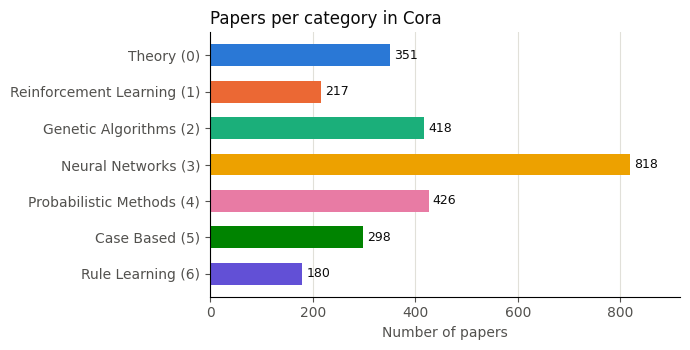

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ids = list(range(num_classes))
counts = papers_per_class.tolist()
ax.barh(ids, counts, height=0.6, color=CATEGORY_COLORS)
ax.set_yticks(ids, [f"{category(c)} ({c})" for c in ids], color=INK)
ax.invert_yaxis()
for c, value in zip(ids, counts):
    ax.text(value + 8, c, str(value), va="center", fontsize=9, color=INK)
ax.set_xlabel("Number of papers", color=MUTED)
ax.set_xlim(0, max(counts) * 1.12)
ax.set_title("Papers per category in Cora", loc="left", color=INK)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED)
fig.tight_layout()
plt.show()

**Figure A.** Neural Networks is the largest category (818 papers, 30% of the graph), almost twice the size of the next largest one, Probabilistic Methods (426); Rule Learning (180) and Reinforcement Learning (217) are the smallest.

## 5. Features

The **features** of a node form a binary bag-of-words vector over a fixed vocabulary of 1433 words: entry 1 means that the word occurs in the paper. The sum of a row is therefore the number of **distinct vocabulary words** present in the paper, not the total number of words in it. The words themselves are not part of the dataset: only their positions in the vector are known.

Here the raw features are examined as they are. How to preprocess them for the model is decided in the next stage.

In [7]:
assert torch.isfinite(x).all(), "Features must be finite."

words_per_paper = x.sum(dim=1)

print(f"Vocabulary size (features): {num_features}")
print(f"Binary features: {bool(((x == 0) | (x == 1)).all())}")
print(
    f"Vocabulary words per paper: min {int(words_per_paper.min())}, "
    f"mean {words_per_paper.mean().item():.1f}, max {int(words_per_paper.max())}"
)

Vocabulary size (features): 1433
Binary features: True
Vocabulary words per paper: min 1, mean 18.2, max 30


## 6. Public split and the transductive setting

The public split assigns nodes to three disjoint sets:

- **train**: labels used to optimize the model parameters;
- **validation**: labels used to select the model and for early stopping;
- **test**: labels used only for the final evaluation, never for tuning.

The setting is **transductive**. The whole graph is available during training. Nodes outside the three masks are kept: their features and links can take part in passing information along the graph, but their labels are not used for training or for the metrics computed on the given masks.

In [8]:
masks = {"train": data.train_mask, "validation": data.val_mask, "test": data.test_mask}

for name, mask in masks.items():
    assert mask.shape == (num_nodes,) and mask.dtype == torch.bool, f"The {name} mask must be a boolean vector over all nodes."
assert not (data.train_mask & data.val_mask).any(), "Train and validation masks overlap."
assert not (data.train_mask & data.test_mask).any(), "Train and test masks overlap."
assert not (data.val_mask & data.test_mask).any(), "Validation and test masks overlap."

outside = ~(data.train_mask | data.val_mask | data.test_mask)
masks["outside masks"] = outside

for name, mask in masks.items():
    print(f"{name.capitalize():<15}{int(mask.sum()):>6} nodes")

Train             140 nodes
Validation        500 nodes
Test             1000 nodes
Outside masks    1068 nodes


## 7. Node degrees

The **degree** of a node is the number of its distinct neighbours in the undirected graph. Because every undirected edge appears once with each endpoint as `source`, it equals the number of `edge_index` entries that start at the node.

The bar chart groups degrees into intervals of doubling width (1, 2–3, 4–7, …). Each bar shows the number of papers in that interval, not a probability density; no degree values are left out. High degree means many distinct neighbours in this undirected representation, not necessarily many received citations.

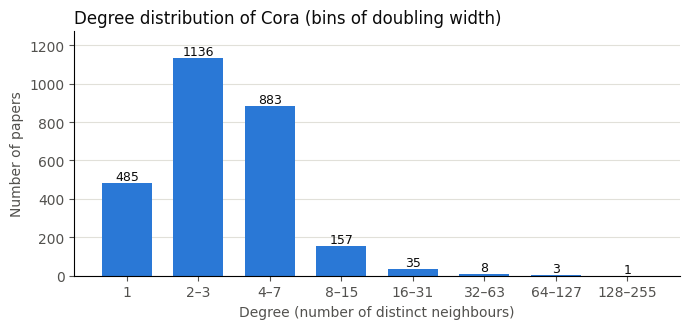

Degree: min 1, median 3, mean 3.90, max 168
Papers with degree above 10: 96


In [9]:
degree = torch.bincount(edge_index[0], minlength=num_nodes)
max_degree = int(degree.max())

edges = [1]
while edges[-1] <= max_degree:
    edges.append(edges[-1] * 2)
bin_counts = [int(((degree >= lo) & (degree < hi)).sum()) for lo, hi in zip(edges[:-1], edges[1:])]
bin_labels = [str(lo) if hi - lo == 1 else f"{lo}–{hi - 1}" for lo, hi in zip(edges[:-1], edges[1:])]
assert sum(bin_counts) == num_nodes, "Every node must fall into one bin."

fig, ax = plt.subplots(figsize=(7, 3.4))
positions = range(len(bin_counts))
ax.bar(positions, bin_counts, width=0.7, color="#2a78d6")
for p, value in zip(positions, bin_counts):
    ax.text(p, value + 15, str(value), ha="center", fontsize=9, color=INK)
ax.set_xticks(list(positions), bin_labels, color=INK)
ax.set_xlabel("Degree (number of distinct neighbours)", color=MUTED)
ax.set_ylabel("Number of papers", color=MUTED)
ax.set_ylim(0, max(bin_counts) * 1.12)
ax.set_title("Degree distribution of Cora (bins of doubling width)", loc="left", color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED)
fig.tight_layout()
plt.show()

print(f"Degree: min {int(degree.min())}, median {int(degree.median())}, mean {degree.float().mean().item():.2f}, max {max_degree}")
print(f"Papers with degree above 10: {int((degree > 10).sum())}")

**Figure B.** Most papers have only a few neighbours: the median degree is 3, and every paper has at least one link. A small number of papers are linked to many others, up to 168 neighbours, so the distribution has a long right tail.

## 8. Example nodes and edges

**Example nodes.** Rule: the smallest node index in each group (train, validation, test, outside masks). In the public split, the training nodes are simply the first indices of the dataset, so taking "the first five nodes" would show training nodes only.

In [10]:
def group_of(node: int) -> str:
    for name, mask in masks.items():
        if mask[node]:
            return name
    raise ValueError(f"Node {node} is in no group.")


examples = [int(torch.nonzero(mask)[0]) for mask in masks.values()]

print(f"{'Node':>6}  {'Category':<24}{'Group':<15}{'Active features':>16}{'Neighbours':>12}")
for node in examples:
    print(
        f"{node:>6}  {category(int(y[node])):<24}{group_of(node):<15}"
        f"{int(words_per_paper[node]):>16}{int(degree[node]):>12}"
    )

  Node  Category                Group           Active features  Neighbours
     0  Neural Networks         train                         9           3
   140  Probabilistic Methods   validation                   18           2
  1708  Neural Networks         test                         20           6
   640  Neural Networks         outside masks                22           6


**Active features of one node.** The numbers below are positions in the 1433-dimensional binary vector of node 0 where the value is 1. They are not words or text of the paper: the vocabulary is not included in the dataset.

In [11]:
active = torch.nonzero(x[0]).flatten().tolist()
print(f"Node 0 has {len(active)} active features; the first {min(8, len(active))} positions: {active[:8]}")

Node 0 has 9 active features; the first 8 positions: [19, 81, 146, 315, 774, 877, 1194, 1247]


**Example edges.** Rule: the first five unique undirected pairs `(u, v)` with `u < v` in lexicographic order. Each pair is shown with the categories of both papers. The rule is not meant to be representative: these examples say nothing about how often linked papers share a category.

In [12]:
undirected = sorted((u, v) for u, v in pairs if u < v)
assert len(undirected) == num_edges

for u, v in undirected[:5]:
    print(f"({u:>4}, {v:>4})   {category(int(y[u])):<24}{category(int(y[v]))}")

u, v = undirected[0]
columns = [j for j in range(num_entries) if {int(edge_index[0, j]), int(edge_index[1, j])} == {u, v}]
print(f"\nThe undirected edge {{{u}, {v}}} is stored in {len(columns)} edge_index columns:")
for j in columns:
    print(f"  column {j}: ({int(edge_index[0, j])}, {int(edge_index[1, j])})")

(   0,  633)   Neural Networks         Neural Networks
(   0, 1862)   Neural Networks         Neural Networks
(   0, 2582)   Neural Networks         Neural Networks
(   1,    2)   Probabilistic Methods   Probabilistic Methods
(   1,  652)   Probabilistic Methods   Probabilistic Methods

The undirected edge {0, 633} is stored in 2 edge_index columns:
  column 0: (633, 0)
  column 2569: (0, 633)


## 9. A local neighbourhood

Rule: node 0, all its direct neighbours, and all edges between these nodes. Colors show categories, labels show node indices, and the central node is drawn larger with a dark outline. The layout uses a fixed seed. This is one chosen local neighbourhood, not a representative sample of the whole graph.

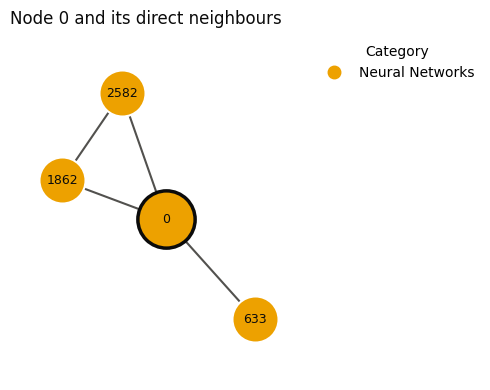

  Node  Category                Group           Degree
     0  Neural Networks         train                3
   633  Neural Networks         validation           3
  1862  Neural Networks         test                 4
  2582  Neural Networks         test                 3
Edges between the selected nodes: 4


In [13]:
center = 0
neighbourhood = [center] + sorted(set(edge_index[1, edge_index[0] == center].tolist()))
selected = set(neighbourhood)
local_edges = [(a, b) for a, b in undirected if a in selected and b in selected]

graph = nx.Graph()
graph.add_nodes_from(neighbourhood)
graph.add_edges_from(local_edges)
layout = nx.spring_layout(graph, seed=0)

fig, ax = plt.subplots(figsize=(5, 4))
nx.draw_networkx_edges(graph, layout, ax=ax, edge_color=MUTED, width=1.5)
for node in neighbourhood:
    is_center = node == center
    nx.draw_networkx_nodes(
        graph, layout, nodelist=[node], ax=ax,
        node_size=1700 if is_center else 1100,
        node_color=CATEGORY_COLORS[int(y[node])],
        edgecolors=INK if is_center else "white",
        linewidths=2.5 if is_center else 1.5,
    )
nx.draw_networkx_labels(graph, layout, ax=ax, font_size=9, font_color=INK)
present = sorted({int(y[n]) for n in neighbourhood})
handles = [
    plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=CATEGORY_COLORS[c], label=category(c))
    for c in present
]
ax.legend(handles=handles, title="Category", loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.set_title(f"Node {center} and its direct neighbours", loc="left", color=INK)
ax.margins(0.2)
ax.axis("off")
fig.tight_layout()
plt.show()

print(f"{'Node':>6}  {'Category':<24}{'Group':<15}{'Degree':>7}")
for node in neighbourhood:
    print(f"{node:>6}  {category(int(y[node])):<24}{group_of(node):<15}{int(degree[node]):>7}")
print(f"Edges between the selected nodes: {len(local_edges)}")

**Figure C.** Node 0 has three neighbours; besides the three edges to node 0, one more edge links neighbours 1862 and 2582. In this particular neighbourhood all four papers belong to Neural Networks. One small neighbourhood cannot show how categories are distributed over the links of the whole graph.

## 10. Summary of the loaded data

In [14]:
summary = {
    "Nodes": num_nodes,
    "Undirected edges": num_edges,
    "Features": num_features,
    "Classes": num_classes,
    "Train nodes": int(data.train_mask.sum()),
    "Validation nodes": int(data.val_mask.sum()),
    "Test nodes": int(data.test_mask.sum()),
    "Nodes outside the masks": int(outside.sum()),
}
for name, value in summary.items():
    print(f"{name:<25}{value:>6}")
print(f"{'Labelled for training':<25}{summary['Train nodes'] / num_nodes:>6.1%}")

Nodes                      2708
Undirected edges           5278
Features                   1433
Classes                       7
Train nodes                 140
Validation nodes            500
Test nodes                 1000
Nodes outside the masks    1068
Labelled for training      5.2%


## 11. Conclusions and next step

- **Task.** Predict the topic of each paper, one of 7 categories, from its word features and its citation links.
- **Little supervision.** Only a small fraction of the nodes have training labels (20 per category); validation and test labels are reserved for model selection and final evaluation. The full category sizes are unbalanced.
- **Sparse, uneven links.** Most papers have only a few neighbours, while a few have many.
- **Why the graph may help.** All nodes, including those outside the masks, are available through the graph, so a GCN can combine the features of a paper with those of its neighbours, while a model that sees only the features of a single paper cannot. Whether and how much this helps is measured in later stages, not here.

The next stage implements the GCN layer: it adds self-loops, normalizes the adjacency matrix and decides how to preprocess the features.

## References

- **Cora (original corpus):** A. K. McCallum, K. Nigam, J. Rennie, K. Seymore. *Automating the construction of internet portals with machine learning.* Information Retrieval 3(2), 2000.
- **This Cora selection and the category names:** LINQS release `cora.tgz` (<https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz>), README and `cora.content`; described in P. Sen, G. Namata, M. Bilgic, L. Getoor, B. Gallagher, T. Eliassi-Rad. *Collective classification in network data.* AI Magazine 29(3), 2008.
- **Planetoid files and public split:** Z. Yang, W. W. Cohen, R. Salakhutdinov. *Revisiting semi-supervised learning with graph embeddings.* ICML 2016; data from <https://github.com/kimiyoung/planetoid>.
- **Loader:** M. Fey, J. E. Lenssen. *Fast graph representation learning with PyTorch Geometric.* 2019 (`torch_geometric.datasets.Planetoid`).
- **GCN:** T. N. Kipf, M. Welling. *Semi-supervised classification with graph convolutional networks.* ICLR 2017.

## Library versions

In [15]:
import platform

import matplotlib
import numpy
import scipy
import torch_geometric

print(
    f"Python {platform.python_version()} | PyTorch {torch.__version__} | PyG {torch_geometric.__version__} | "
    f"NumPy {numpy.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__} | NetworkX {nx.__version__}"
)

Python 3.13.16 | PyTorch 2.11.0+cpu | PyG 2.8.1 | NumPy 2.1.3 | SciPy 1.16.3 | Matplotlib 3.10.0 | NetworkX 3.7
